# Breast cancer segmentation

Try using segmentation-models-pytorch library to perform segmentation on breast ultrasounds (mammagrams) to identify:
- malignant lesion
- benign lesion
- normal
breast areas.

## Install packages

In [1]:
#%%capture
#!pip install segmentation-models-pytorch lightning albumentations

In [2]:
from pathlib import Path
from PIL import Image, ImageChops
import os
from typing import Tuple
import random

import torch
import numpy as np
import albumentations as A
import matplotlib.pyplot as plt
from torch.utils.data import Dataset as BaseDataset, DataLoader, Subset, random_split
from torch.optim import lr_scheduler
from torchvision.datasets import ImageFolder
from torchvision.datasets.folder import pil_loader
#import segmentation_models_pytorch as smp
import pytorch_lightning as pl

# Set seeds for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

## Data

The data comes from this [kaggle competition](https://www.kaggle.com/competitions/breast-cancer-us-classification-ml-4-im-2025-2026/data) dataset. The data should be downloaded into the ./data directory adjacent to this notebook.

The data is under the ./data/complete_set directory with training and test already separated. The training data has 547 images, and more masks.

Because the data directories are not setup the same way as a normal.

## SegmentationImageFolder Dataset

In [3]:
class SegmentationImageFolder(ImageFolder):
    # Class labels for multi-class segmentation
    # 0 = background, 1 = benign, 2 = malignant
    SEGMENTATION_CLASSES = ['background', 'benign', 'malignant']
    NUM_CLASSES = 3
    
    def __init__(self, root, transform=None, loader=None):
        if loader is None:
            super().__init__(root, transform=None)  # Don't pass transform to parent
        else:
            super().__init__(root, transform=None, loader=loader)
        
        # Store albumentations transform separately
        self.albu_transform = transform
        
        # Filter out masks from the self.samples list
        self.samples = [(path, target) for path, target in self.samples 
                        if not '_mask' in path]
        self.imgs = self.samples  # For compatibility with ImageFolder
        
        # Number of segmentation classes (background + benign + malignant)
        self.num_classes = self.NUM_CLASSES

        self.class_to_name = {i: j for i, j in enumerate(self.SEGMENTATION_CLASSES)}

    @staticmethod
    def get_mean_std(root):
        """Calculate mean and std of the dataset after applying transform."""
        means = []
        stds = []
        
        pngs = list(Path(root).rglob("*.png"))
        samples = [png for png in pngs if not '_mask' in png.name]
        for path in samples:
            img = pil_loader(path)
            img_np = np.array(img)
            img_tensor = torch.from_numpy(img_np).permute(2, 0, 1).float() / 255.0
            img_np = img_tensor.numpy()
            means.append(np.mean(img_np, axis=(1, 2)))  # Mean per channel: (C, H, W) -> (C,)
            stds.append(np.std(img_np, axis=(1, 2)))    # Std per channel: (C, H, W) -> (C,)
        
        mean = np.mean(means, axis=0)
        std = np.mean(stds, axis=0)
        
        return mean, std      

    
    def __getitem__(self, index):
        # Get original image path and class label
        path, target = self.samples[index]
        
        # Load the image
        sample = self.loader(path)
        
        # Find all corresponding masks
        masks = self._find_masks(path)

        # Combine masks if multiple exist using max (union of all masks)
        if len(masks) > 1:
            combined = masks[0]
            for mask in masks[1:]:
                combined = ImageChops.lighter(combined, mask)  # Takes max of each pixel
            masks = combined
        elif len(masks) == 1:
            masks = masks[0]
        else:
            # No mask found - create empty mask
            masks = None
        
        return sample, masks, target
    
    def _find_masks(self, image_path):
        """Find all mask files corresponding to an image."""
        image_path = Path(image_path)
        
        # Extract the base name, e.g., "benign (4).png" -> "benign (4)"
        mask_patt = f"{image_path.stem}_mask*.png"
        
        # Find all masks: base_name + "_mask.png" and base_name + "_mask_N.png"
        mask_files = list(image_path.parent.glob(mask_patt))
        
        masks = [Image.open(mask_file).convert('L') for mask_file in mask_files]
        
        return masks

We want dataset without transforms so that we can calculate mean and std on untransformed data, and split into training and validation sets. We'll then use a new class called **SubsetWithTransform** to contain the train and validation subsets and their respective transforms.

In [4]:
breast_ds = SegmentationImageFolder(
    "/home/michaelw/prog/kaggle/breast_cancer/data/training_set",
    transform=None,  # Transforms for train and val applied in subset class
)
print(breast_ds)

Dataset SegmentationImageFolder
    Number of datapoints: 547
    Root location: /home/michaelw/prog/kaggle/breast_cancer/data/training_set


Check the balance of the classes in the breast_ds:

In [5]:
def get_class_counts(ds: BaseDataset):
    if isinstance(ds, Subset):
        dset = ds.dataset  # Get the underlying dataset if it's a Subset
        samples = [dset.samples[i] for i in ds.indices]
    else: # ds is a SegmentationImageFolder
        samples = ds.samples
        dset = ds  # Use the dataset directly if it's not a Subset
    num_classes = {"benign": 0, "malignant": 1}
    for _, target in samples:
        num_classes[dset.class_to_name[target + 1]] += 1
    return num_classes

c_counts = get_class_counts(breast_ds)
c_counts

{'benign': 387, 'malignant': 161}

Create the **SubsetWithTransform** class:

In [6]:
class SubsetWithTransform(BaseDataset):
    """A subset of a dataset with a specific transform applied."""

    def __init__(self, subset: Subset, transform=None):
        # subset should be a subset WITHOUT transform
        self.subset = subset
        self.transform = transform

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        sample, mask, target = self.subset[idx]
        # Convert to numpy arrays for albumentations
        sample_np = np.array(sample)
        mask_np = np.array(mask) if mask is not None else np.zeros(sample_np.shape[:2], dtype=np.uint8)
        
        # Encode class into mask for multi-class segmentation:
        # 0 = background, 1 = benign (target=0), 2 = malignant (target=1)
        mask_np = np.where(mask_np > 0, target + 1, 0).astype(np.uint8)
        if self.transform:
            transformed = self.transform(image=sample_np, mask=mask_np)
            sample = transformed['image']
            mask = transformed['mask']
        else:
            sample = torch.from_numpy(sample_np).permute(2, 0, 1).float()
            mask = torch.from_numpy(mask_np)
        return sample, mask, target


Create train and val datasets:

In [7]:
def get_train_val_ds(ds: SegmentationImageFolder, train_prop=0.8)-> list[Subset]:
    seed = 42
    generator = torch.Generator().manual_seed(seed)
    total_samples = len(ds)
    num_train = int(train_prop * total_samples)
    num_val = total_samples - num_train
    return random_split(ds, [num_train, num_val])


In [8]:
train_ds, val_ds = get_train_val_ds(breast_ds)
len(train_ds), len(val_ds)

(437, 110)

Check balance of train and val datasets:

In [9]:
train_counts = get_class_counts(train_ds)
val_counts = get_class_counts(val_ds)
train_benign_to_malign_ratio = train_counts['benign'] / train_counts['malignant'] if train_counts['malignant'] > 0 else float('inf')
print(f"Train Class Counts: {train_counts}")
print(f"Validation Class Counts: {val_counts}")
print(f"Train Benign to Malignant Ratio: {train_benign_to_malign_ratio:.2f}")

Train Class Counts: {'benign': 310, 'malignant': 128}
Validation Class Counts: {'benign': 77, 'malignant': 34}
Train Benign to Malignant Ratio: 2.42


The classes are unbalanced. Get class weights for the classes:

In [10]:
# Calculate class weights for handling class imbalance
# Format: [background, benign, malignant]
# Using inverse frequency weighting

total_samples = train_counts['benign'] + train_counts['malignant']
benign_weight = total_samples / (2 * train_counts['benign'])
malignant_weight = total_samples / (2 * train_counts['malignant'])

# Background class gets weight of 1.0 (neutral)
class_weights = [1.0, benign_weight, malignant_weight]

print(f"Class weights: [background={class_weights[0]:.3f}, benign={class_weights[1]:.3f}, malignant={class_weights[2]:.3f}]")
print(f"Malignant class will have {class_weights[2]/class_weights[1]:.2f}x more importance than benign")

Class weights: [background=1.000, benign=0.706, malignant=1.711]
Malignant class will have 2.42x more importance than benign


Create some transforms for the images and masks using transforms.V2 to allow applying the same transforms to masks and images:

In [11]:
import albumentations as A
from albumentations.pytorch import ToTensorV2

def get_transformations(mean, std):
    """
    Returns two sets of image transformation pipelines: one with basic preprocessing and another with additional 
    data augmentation.

    Args:
        mean: Sequence of mean values for normalization.
        std: Sequence of standard deviation values for normalization.

    Returns:
        main_transform: Transformation pipeline with resizing, tensor conversion, and normalization.
        transform_with_augmentation: Transformation pipeline including random vertical flip, random rotation,
                resizing, tensor conversion, and normalization.
    """
    main_transform = A.Compose([
        A.Resize(256, 256),
        A.Normalize(mean=mean, std=std),
        ToTensorV2(),
    ])

    transform_with_augmentation = A.Compose([
        A.RandomBrightnessContrast(brightness_limit=0.4, contrast_limit=0.4, p=0.5),  # Larger brightness and contrast variations
        A.CLAHE(clip_limit=2.0, tile_grid_size=(8, 8), p=0.2),  # Apply CLAHE for local contrast enhancement
        A.RandomGamma(gamma_limit=(80, 120), p=0.3),  # Adjust Gamma
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.Rotate(limit=15, p=0.5),
        *main_transform.transforms,  # Reuse the main transform for resizing, normalization, and tensor conversion
    ])
    
    return main_transform, transform_with_augmentation

In [12]:
mean, std = SegmentationImageFolder.get_mean_std("/home/michaelw/prog/kaggle/breast_cancer/data/complete_set")
main_transform, transform_with_augmentation = get_transformations(mean, std)
print("Mean:", mean)
print("Std:", std)
print("Main Transform:", main_transform)
print("Transform with Augmentation:", transform_with_augmentation)

Mean: [0.33033508 0.3303265  0.3302719 ]
Std: [0.20433462 0.20433684 0.20429572]
Main Transform: Compose([
  Resize(p=1.0, area_for_downscale=None, height=256, interpolation=1, mask_interpolation=0, width=256),
  Normalize(p=1.0, max_pixel_value=255.0, mean=(0.3303350806236267, 0.33032649755477905, 0.3302718997001648), normalization='standard', std=(0.20433461666107178, 0.20433683693408966, 0.20429572463035583)),
  ToTensorV2(p=1.0, transpose_mask=False),
], p=1.0, bbox_params=None, keypoint_params=None, additional_targets={}, is_check_shapes=True)
Transform with Augmentation: Compose([
  RandomBrightnessContrast(p=0.5, brightness_by_max=True, brightness_limit=(-0.4, 0.4), contrast_limit=(-0.4, 0.4), ensure_safe_range=False),
  CLAHE(p=0.2, clip_limit=(1.0, 2.0), tile_grid_size=(8, 8)),
  RandomGamma(p=0.3, gamma_limit=(80.0, 120.0)),
  HorizontalFlip(p=0.5),
  VerticalFlip(p=0.5),
  Rotate(p=0.5, border_mode=0, crop_border=False, fill=0.0, fill_mask=0.0, interpolation=1, limit=(-15.0,

In [13]:
train_dset = SubsetWithTransform(train_ds, transform=transform_with_augmentation)
val_dset = SubsetWithTransform(val_ds, transform=main_transform)

In [14]:
sample, masks, target = train_dset[0]
print(f"Sample type: {type(sample)}, Masks type: {type(masks)}, Target: {target}")

Sample type: <class 'torch.Tensor'>, Masks type: <class 'torch.Tensor'>, Target: 0


In [15]:
def display_samples(
        ds_subset: Subset,
        start_index: int = 0,
        n_samples: int = 3,
        mean: np.ndarray = None,
        std: np.ndarray = None
    ):
    """Display sample(s) and mask(s) side by side.
    
    Args:
        ds: A dataset object that returns tuples (sample, mask, target)
        start_index: Index to start displaying samples from
        n_samples: Number of samples to display
        mean: Mean used for normalization (to reverse it). Shape (C,) or None.
        std: Std used for normalization (to reverse it). Shape (C,) or None.
    """
    n_samples = min(n_samples, len(ds_subset) - start_index)
    fig, axes = plt.subplots(n_samples, 3, figsize=(18, 6 * n_samples))
    data = [ds_subset[i] for i in range(start_index, start_index + n_samples)]
    # Handle single row case (axes is 1D)
    if n_samples == 1:
        axes = axes.reshape(1, -1)
    
    for i, (sample, masks, target) in enumerate(data):
        # Convert tensor to numpy for display (C, H, W) -> (H, W, C)
        img = sample.permute(1, 2, 0).numpy()
        
        # Reverse normalization and scaling if mean/std provided
        if mean is not None and std is not None:
            img = img * std + mean  # Denormalize
        img = np.clip(img, 0, 1)  # Clip to valid range
        
        # Display the sample image
        axes[i, 0].imshow(img)
        axes[i, 0].set_title(f"Sample (Class: {ds_subset.subset.dataset.classes[target]})")
        axes[i, 0].axis('off')
        
        # Display the mask - now (H, W) from albumentations
        mask_img = masks.numpy() if torch.is_tensor(masks) else masks
        axes[i, 1].imshow(mask_img, cmap='gray')
        axes[i, 1].set_title("Mask")
        
        # Display overlay: image with purple mask at 50% opacity
        axes[i, 2].imshow(img)
        # Create purple overlay (normalize mask to 0-1 range)
        mask_float = mask_img.astype(np.float32)
        mask_normalized = mask_float / mask_float.max() if mask_float.max() > 0 else mask_float
        # Create RGBA overlay with purple color (128, 0, 128)
        purple_overlay = np.zeros((*mask_img.shape, 4))
        purple_overlay[..., 0] = 0.5  # Red channel
        purple_overlay[..., 1] = 0.0  # Green channel
        purple_overlay[..., 2] = 0.5  # Blue channel
        purple_overlay[..., 3] = mask_normalized * 0.5  # Alpha channel (50% opacity)
        axes[i, 2].imshow(purple_overlay)
        axes[i, 2].set_title("Overlay")
        
        axes[i, 1].axis('off')
        axes[i, 2].axis('off')
    
    plt.tight_layout()
    plt.show()

# Example usage:
# display_samples(ds, mean=mean, std=std)

Do some more visualisation with a 3rd panel overlapping the mask with suitable transparency and colour.

#### Train Dataset

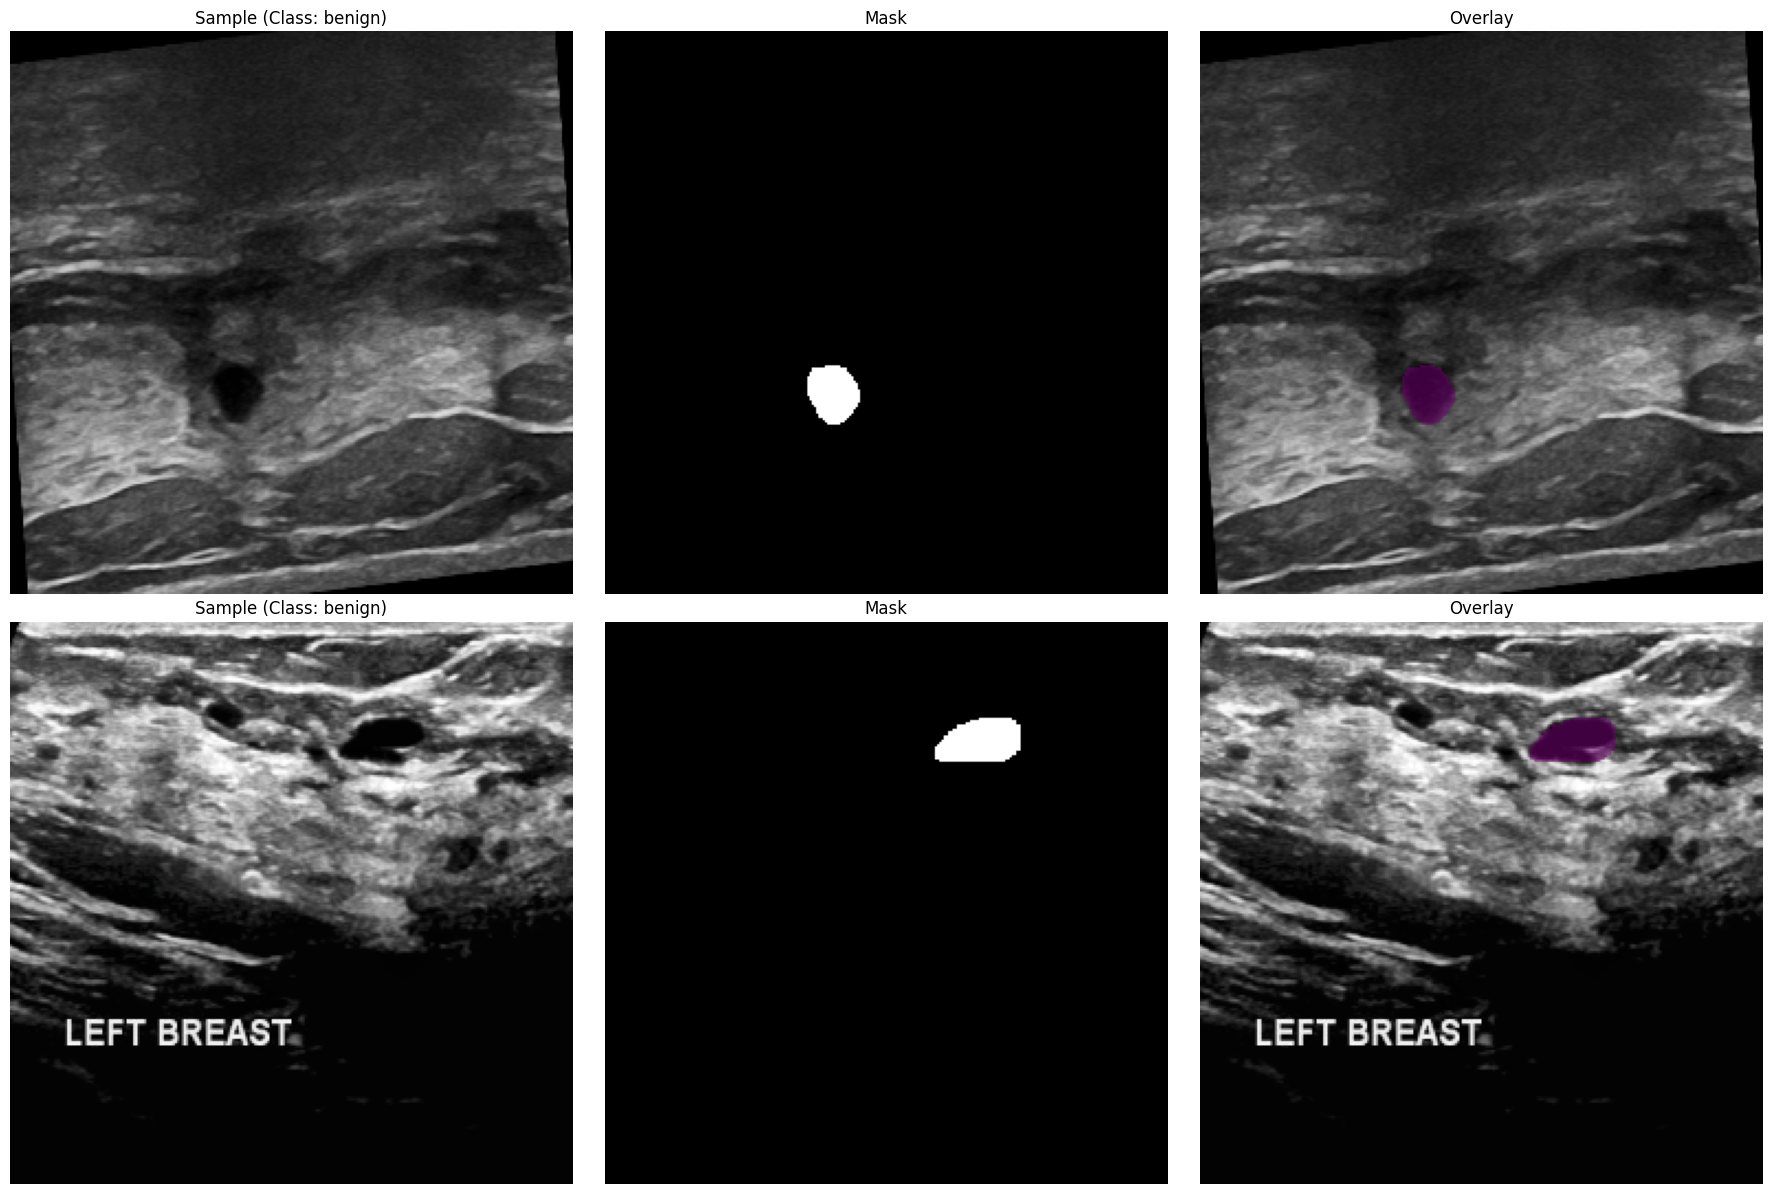

In [16]:
display_samples(train_dset, start_index=95, n_samples=2, mean=mean, std=std)

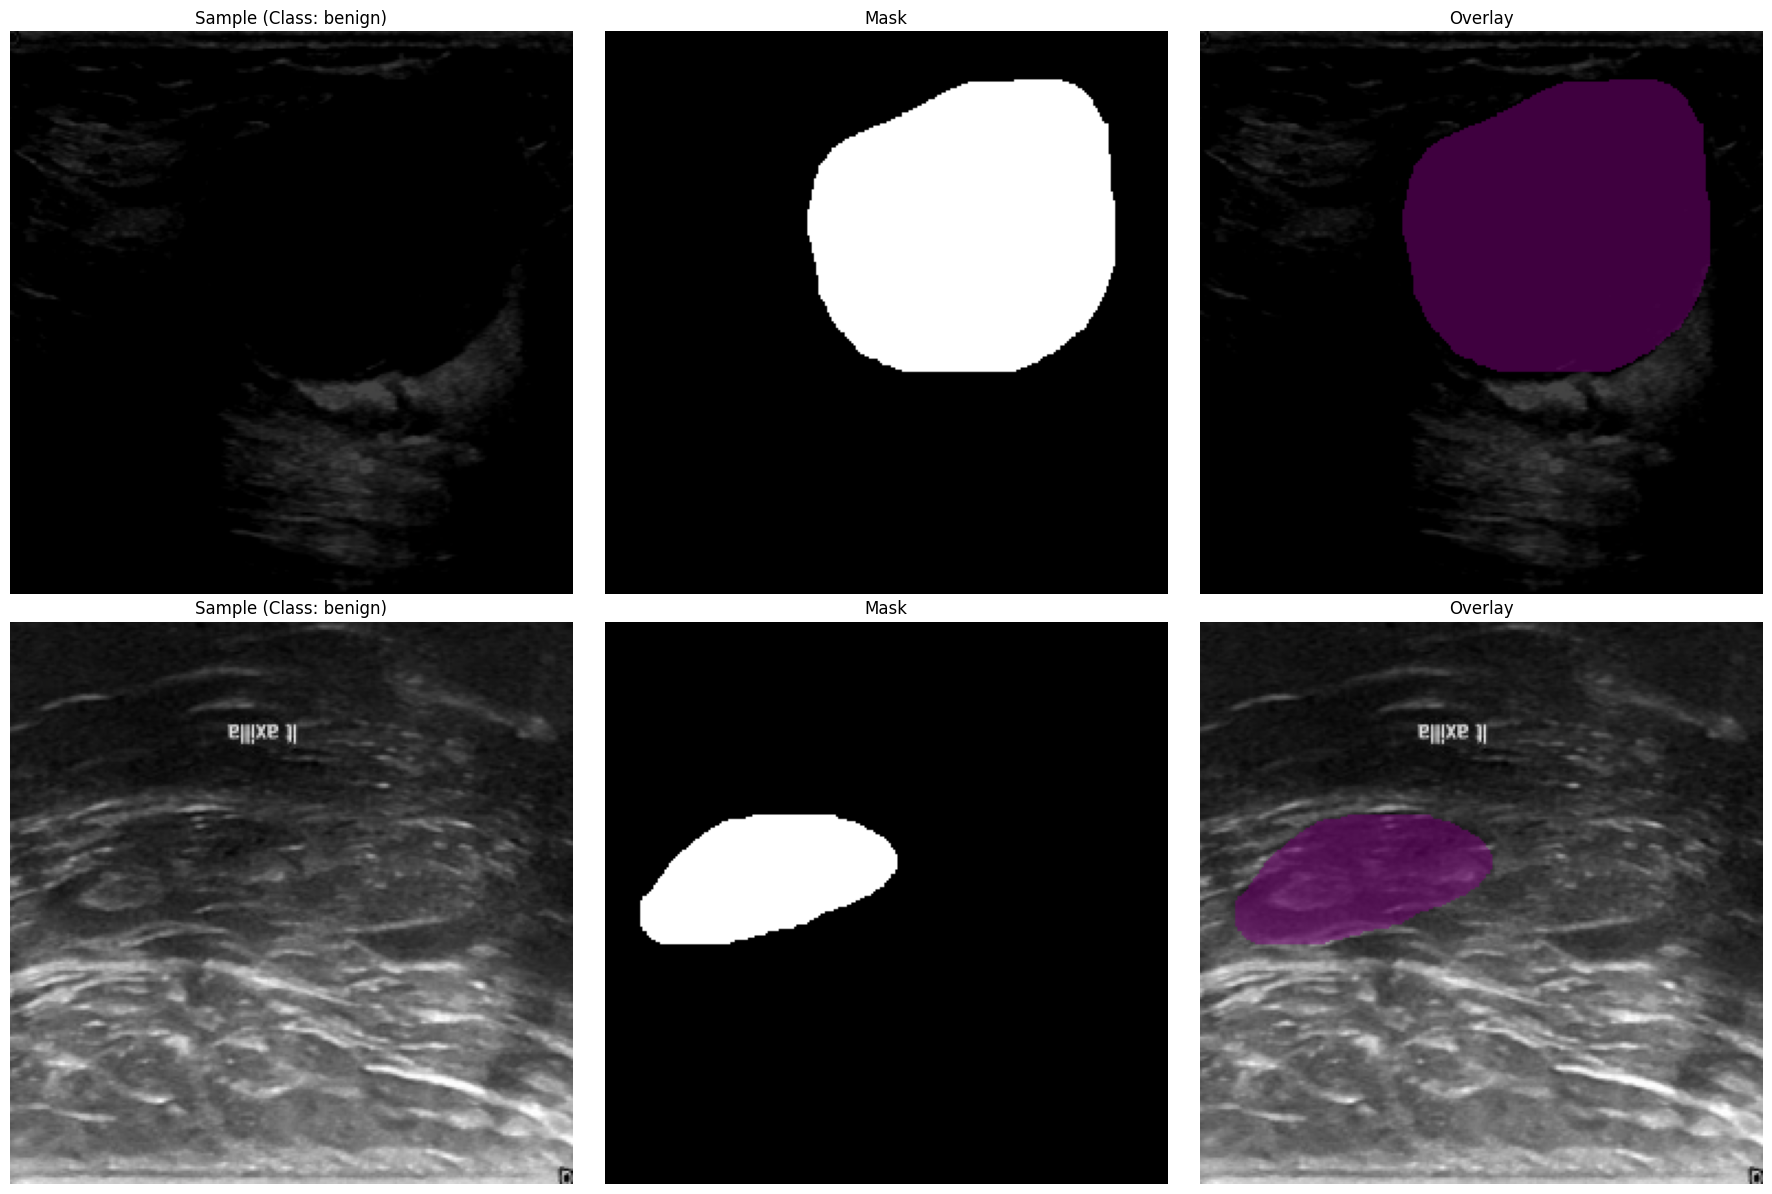

In [17]:
display_samples(train_dset, start_index=347, n_samples=2, mean=mean, std=std)

#### Validation Dataset

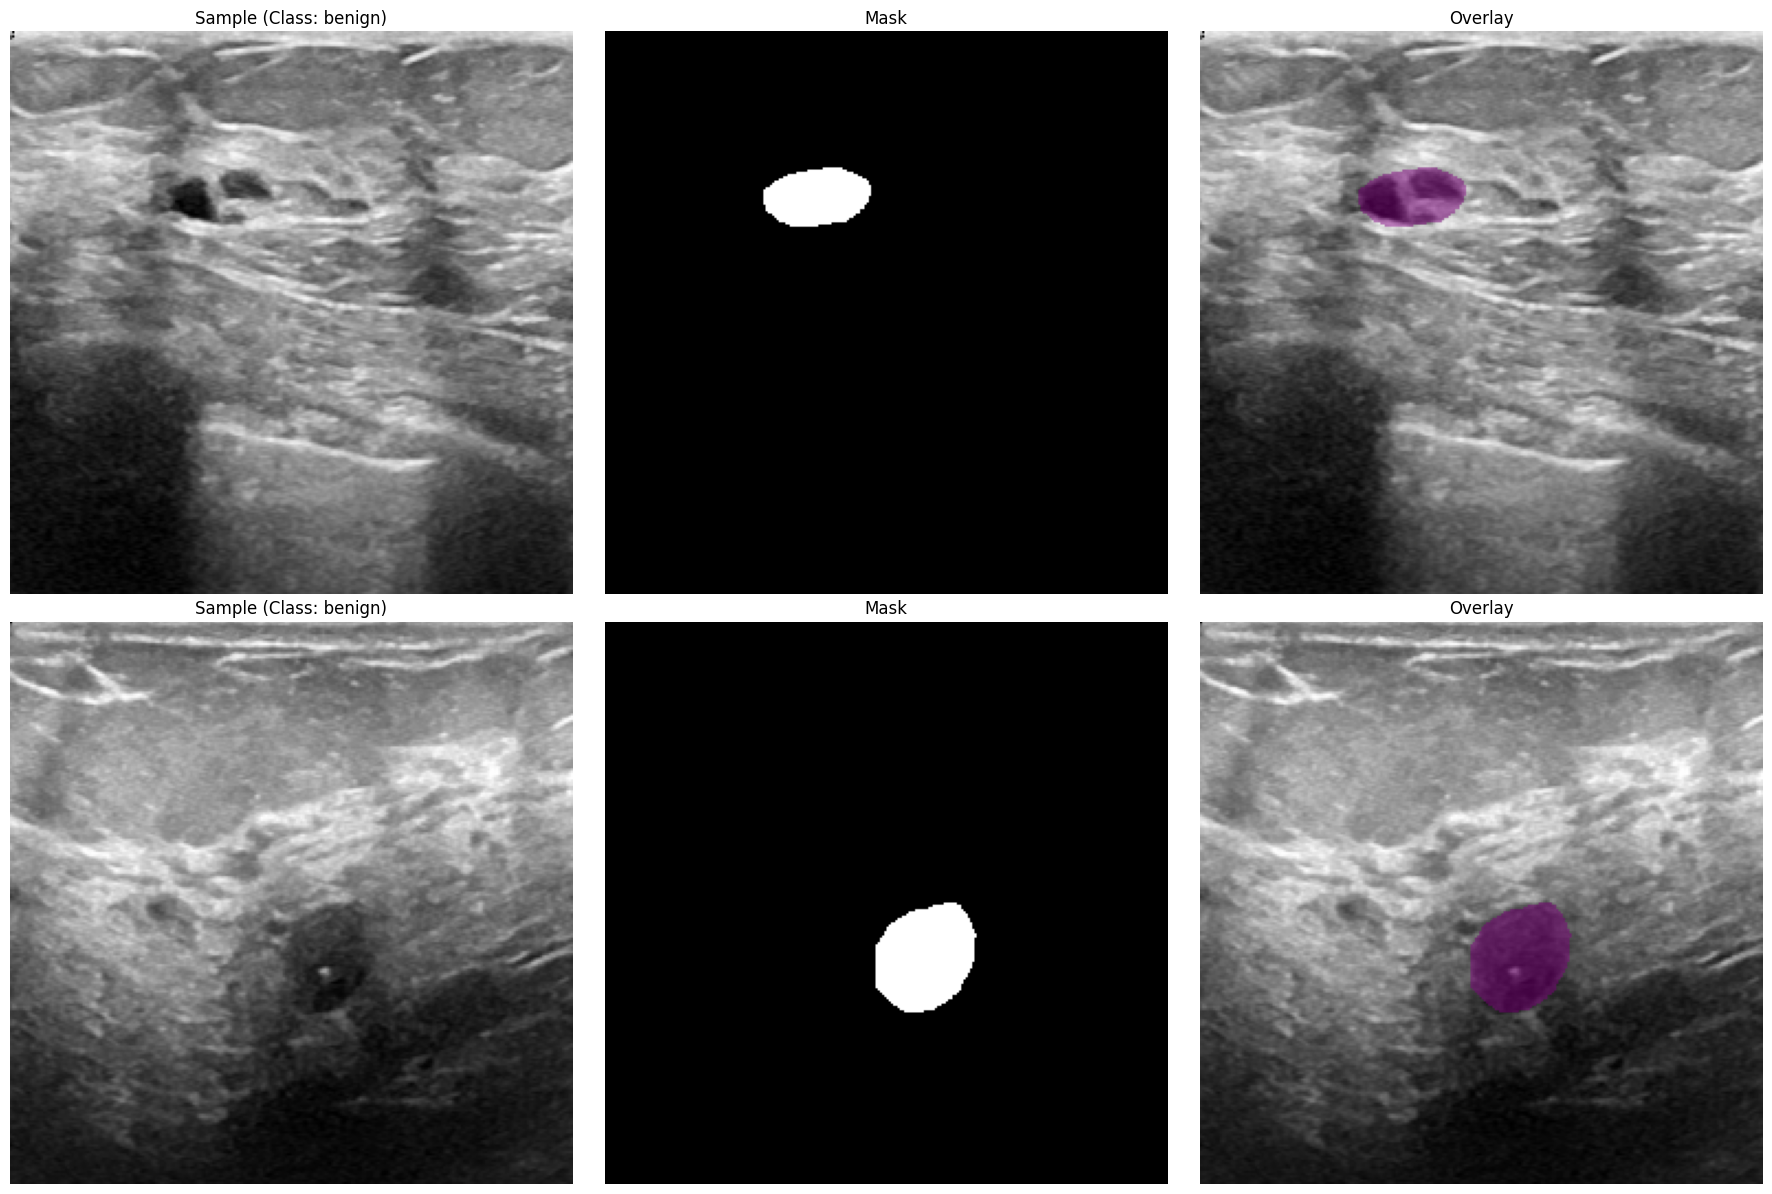

In [18]:
display_samples(val_dset, start_index=0, n_samples=2, mean=mean, std=std)

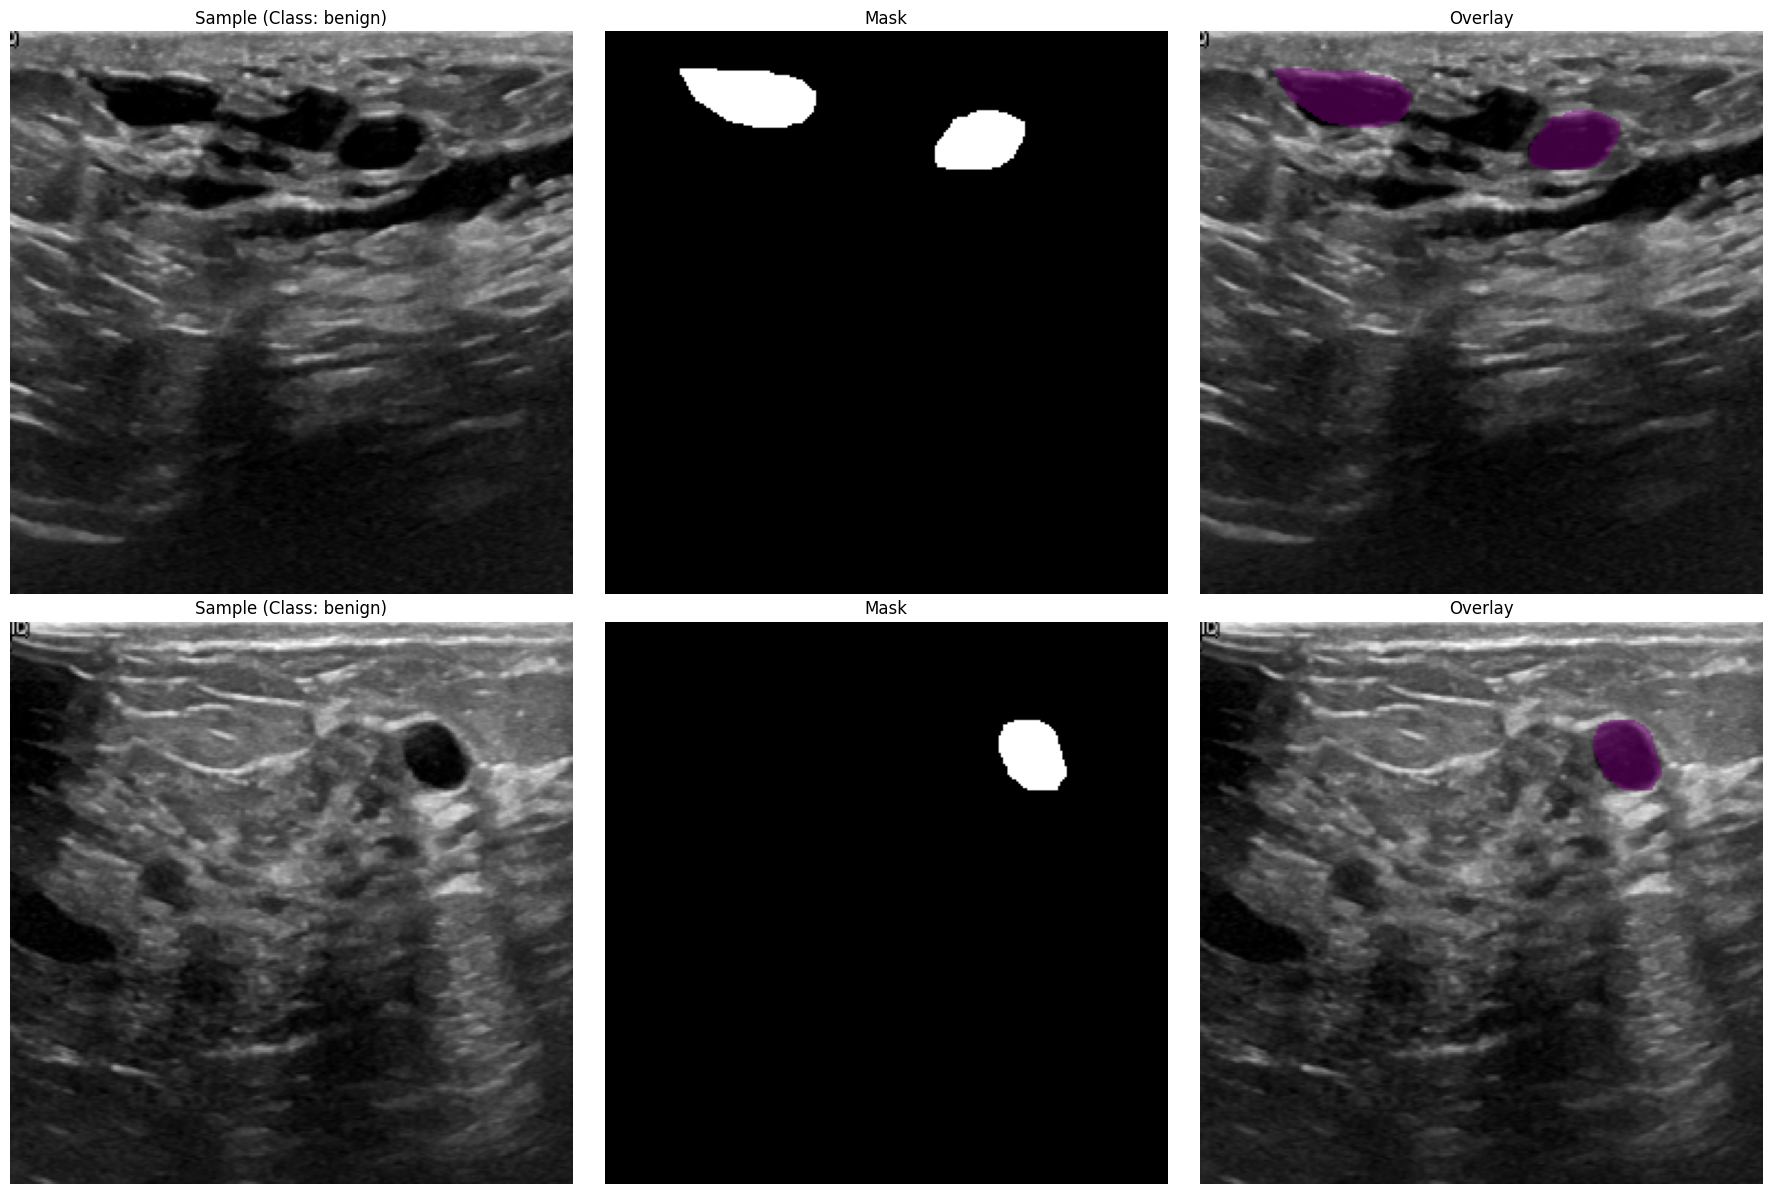

In [19]:
display_samples(val_dset, start_index=80, n_samples=2, mean=mean, std=std)

In [20]:
val_dset.subset.dataset

Dataset SegmentationImageFolder
    Number of datapoints: 547
    Root location: /home/michaelw/prog/kaggle/breast_cancer/data/training_set

### Create data loader

From before we have the ratio of benign to malignant examples in the training set:

In [21]:
print(f"Train Benign to Malignant Ratio: {train_benign_to_malign_ratio:.2f}")

Train Benign to Malignant Ratio: 2.42


FIXME: Come back to addressing class imbalance with the loss function.

Create the train and val datasets, and their respective loaders:

In [22]:
train_loader = DataLoader(train_dset, batch_size=32, shuffle=True, num_workers=23)
val_loader = DataLoader(val_dset, batch_size=32, shuffle=False, num_workers=23)

Have a look at the loaders:

In [23]:
print('=== Train Loader ===')
print(f"Number of batches in train_loader: {len(train_loader)}")
train_dataset = train_loader.dataset
print(f"Number of samples in train_dataset: {len(train_dataset)}")
print(f"Transforms applied to train_dataset: {train_dataset.transform}")
print(f"train_dataset type: {type(train_dataset)}")

print('\n=== Test Loader ===')
print(f"Number of batches in test_loader: {len(val_loader)}")
val_dataset = val_loader.dataset
print(f"Number of samples in val_dataset: {len(val_dataset)}")
print(f"Transforms applied to val_dataset: {val_dataset.transform}")
print(f"val_dataset type: {type(val_dataset)}")

=== Train Loader ===
Number of batches in train_loader: 14
Number of samples in train_dataset: 437
Transforms applied to train_dataset: Compose([
  RandomBrightnessContrast(p=0.5, brightness_by_max=True, brightness_limit=(-0.4, 0.4), contrast_limit=(-0.4, 0.4), ensure_safe_range=False),
  CLAHE(p=0.2, clip_limit=(1.0, 2.0), tile_grid_size=(8, 8)),
  RandomGamma(p=0.3, gamma_limit=(80.0, 120.0)),
  HorizontalFlip(p=0.5),
  VerticalFlip(p=0.5),
  Rotate(p=0.5, border_mode=0, crop_border=False, fill=0.0, fill_mask=0.0, interpolation=1, limit=(-15.0, 15.0), mask_interpolation=0, rotate_method='largest_box'),
  Resize(p=1.0, area_for_downscale=None, height=256, interpolation=1, mask_interpolation=0, width=256),
  Normalize(p=1.0, max_pixel_value=255.0, mean=(0.3303350806236267, 0.33032649755477905, 0.3302718997001648), normalization='standard', std=(0.20433461666107178, 0.20433683693408966, 0.20429572463035583)),
  ToTensorV2(p=1.0, transpose_mask=False),
], p=1.0, bbox_params=None, keypoin

## Create model and train

In [24]:
# Some training hyperparameters
EPOCHS = 50
T_MAX = EPOCHS * len(train_loader)
# Always include the background as a class
OUT_CLASSES = len(SegmentationImageFolder.SEGMENTATION_CLASSES)

In [25]:
import pytorch_lightning as pl
import segmentation_models_pytorch as smp
import torch
import torch.nn as nn
from torch.optim import lr_scheduler

torch.set_float32_matmul_precision("medium")

class BreastCancerMammogramModel(pl.LightningModule):
    def __init__(self, arch, encoder_name, encoder_weights, in_channels, out_classes, class_weights=None, **kwargs):
        super().__init__()
        self.model = smp.create_model(
            arch,
            encoder_name=encoder_name,
            encoder_weights=encoder_weights if encoder_weights else None,
            in_channels=in_channels,
            classes=out_classes,
            **kwargs,
        )

        # Preprocessing parameters for image normalization
        #params = smp.encoders.get_preprocessing_params(encoder_name)
        self.number_of_classes = out_classes
        #self.register_buffer("std", torch.tensor(params["std"]).view(1, 3, 1, 1))
        #self.register_buffer("mean", torch.tensor(params["mean"]).view(1, 3, 1, 1))

        # Loss function for multi-class segmentation
        self.dice_loss = smp.losses.DiceLoss(smp.losses.MULTICLASS_MODE, from_logits=True)
        
        # Add weighted CrossEntropyLoss to handle class imbalance
        if class_weights is not None:
            weight_tensor = torch.tensor(class_weights, dtype=torch.float32)
            self.register_buffer("class_weights", weight_tensor)
            self.ce_loss = nn.CrossEntropyLoss(weight=weight_tensor)
        else:
            self.ce_loss = nn.CrossEntropyLoss()

        # Step metrics tracking
        self.training_step_outputs = []
        self.validation_step_outputs = []
        #self.test_step_outputs = []

    def forward(self, image):
        mask = self.model(image)
        return mask

    def shared_step(self, batch, stage):
        image, mask, _ = batch

        # Ensure that image dimensions are correct
        assert image.ndim == 4  # [batch_size, channels, H, W]

        # Ensure the mask is a long (index) tensor
        mask = mask.long()

        # Mask shape
        assert mask.ndim == 3  # [batch_size, H, W]

        # Predict mask logits
        logits_mask = self.forward(image)

        assert (
            logits_mask.shape[1] == self.number_of_classes
        )  # [batch_size, number_of_classes, H, W]

        # Ensure the logits mask is contiguous
        logits_mask = logits_mask.contiguous()

        # Compute combined loss: Dice + weighted CrossEntropy
        dice = self.dice_loss(logits_mask, mask)
        ce = self.ce_loss(logits_mask, mask)
        loss = dice + ce

        # Apply softmax to get probabilities for multi-class segmentation
        prob_mask = logits_mask.softmax(dim=1)

        # Convert probabilities to predicted class labels
        pred_mask = prob_mask.argmax(dim=1)

        # Compute true positives, false positives, false negatives, and true negatives
        tp, fp, fn, tn = smp.metrics.get_stats(
            pred_mask, mask, mode="multiclass", num_classes=self.number_of_classes
        )

        return {
            "loss": loss,
            "tp": tp,
            "fp": fp,
            "fn": fn,
            "tn": tn,
        }

    def shared_epoch_end(self, outputs, stage):
        # Aggregate step metrics
        tp = torch.cat([x["tp"] for x in outputs])
        fp = torch.cat([x["fp"] for x in outputs])
        fn = torch.cat([x["fn"] for x in outputs])
        tn = torch.cat([x["tn"] for x in outputs])

        # Per-image IoU and dataset IoU calculations
        per_image_iou = smp.metrics.iou_score(
            tp, fp, fn, tn, reduction="micro-imagewise"
        )
        dataset_iou = smp.metrics.iou_score(tp, fp, fn, tn, reduction="micro")

        metrics = {
            f"{stage}_per_image_iou": per_image_iou,
            f"{stage}_dataset_iou": dataset_iou,
        }

        self.log_dict(metrics, prog_bar=True)

    def training_step(self, batch, batch_idx):
        train_loss_info = self.shared_step(batch, "train")
        self.training_step_outputs.append(train_loss_info)
        return train_loss_info

    def on_train_epoch_end(self):
        self.shared_epoch_end(self.training_step_outputs, "train")
        self.training_step_outputs.clear()

    def validation_step(self, batch, batch_idx):
        valid_loss_info = self.shared_step(batch, "valid")
        self.validation_step_outputs.append(valid_loss_info)
        return valid_loss_info

    def on_validation_epoch_end(self):
        self.shared_epoch_end(self.validation_step_outputs, "valid")
        self.validation_step_outputs.clear()

    def test_step(self, batch, batch_idx):
        test_loss_info = self.shared_step(batch, "test")
        self.test_step_outputs.append(test_loss_info)
        return test_loss_info

    def on_test_epoch_end(self):
        self.shared_epoch_end(self.test_step_outputs, "test")
        self.test_step_outputs.clear()

    def configure_optimizers(self):
        optimizer = torch.optim.Adam(self.parameters(), lr=2e-4)
        scheduler = lr_scheduler.CosineAnnealingLR(optimizer, T_max=50, eta_min=1e-5)
        return {
            "optimizer": optimizer,
            "lr_scheduler": {
                "scheduler": scheduler,
                "interval": "step",
                "frequency": 1,
            },
        }


In [26]:
model = BreastCancerMammogramModel(
    arch="UNET", 
    encoder_name="resnet34", 
    encoder_weights="imagenet", 
    in_channels=3, 
    out_classes=OUT_CLASSES,
    class_weights=class_weights
)


### Training

In [27]:
trainer = pl.Trainer(max_epochs=EPOCHS, log_every_n_steps=1)

trainer.fit(
    model,
    train_dataloaders=train_loader,
    val_dataloaders=val_loader,
)

💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
/home/michaelw/.pyenv/versions/py_3_12_8/lib/python3.12/site-packages/pytorch_lightning/trainer/connectors/logger_connector/logger_connector.py:76: Starting from v1.9.0, `tensorboardX` has been removed as a dependency of the `pytorch_lightning` package, due to potential conflicts with other packages in the ML ecosystem. For this reason, `logger=True` will use `CSVLogger` as the default logger, unless the `tensorboard` or `tensorboardX` packages are found. Please `pip install lightning[extra]` or one of them to enable TensorBoard support by default
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name      ┃ Type             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model     │ Unet             │ 24.4 M │ train │     0 │
│ 1 │ dice_loss │ DiceLoss         │      0 │ train │     0 │
│ 2 │ ce_loss   │ CrossEntropyLoss │      0 │ train │     0 │
└───┴───────────┴──────────────────┴────────┴───────┴───────┘

Trainable params: 24.4 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 24.4 M                                                                                               
Total estimated model params size (MB): 97                                                                         
Modules in train mode: 190                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

`Trainer.fit` stopped: `max_epochs=50` reached.


### Validation

In [28]:
# run validation dataset
valid_metrics = trainer.validate(model, dataloaders=val_loader, verbose=False)
print(valid_metrics)

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Output()

[{'valid_per_image_iou': 0.9375325441360474, 'valid_dataset_iou': 0.9340905547142029}]


### Validation visualization

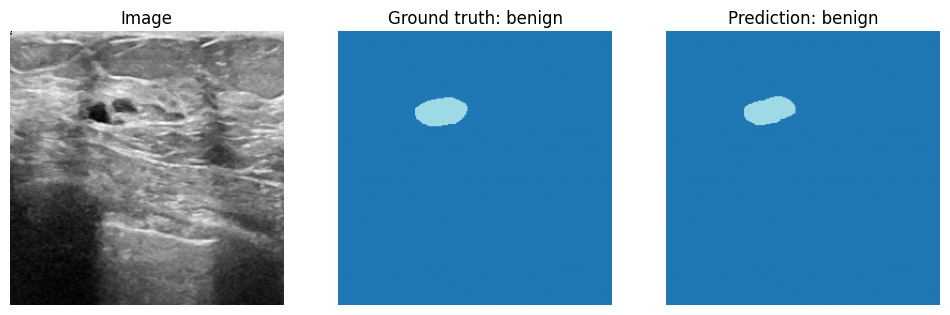

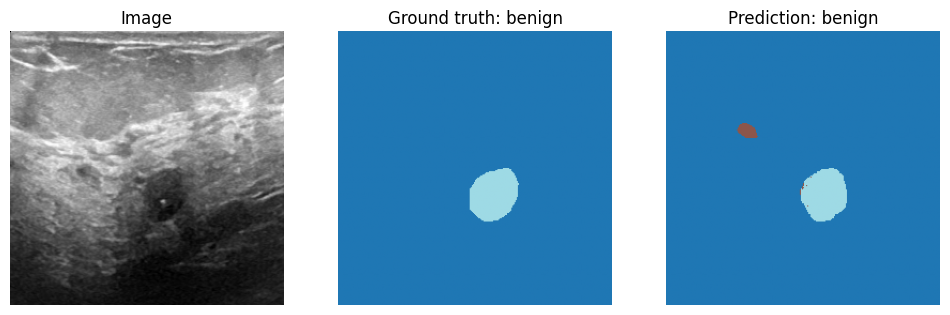

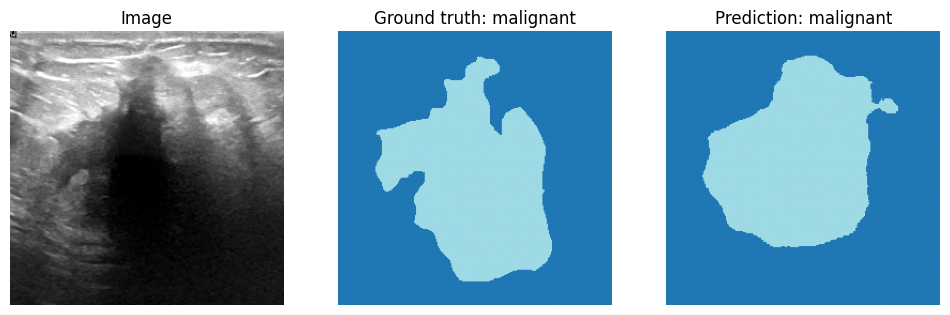

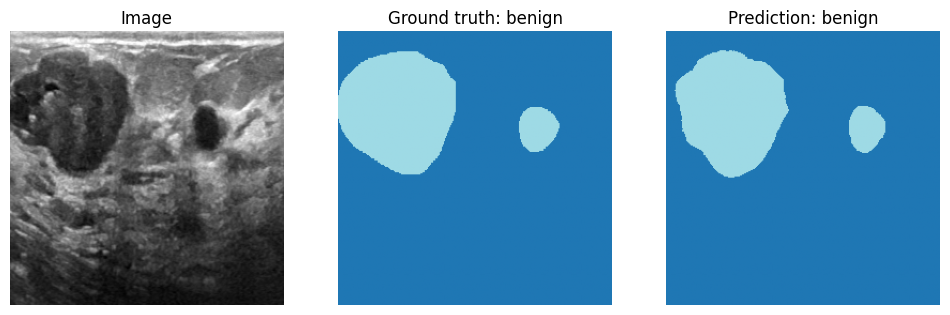

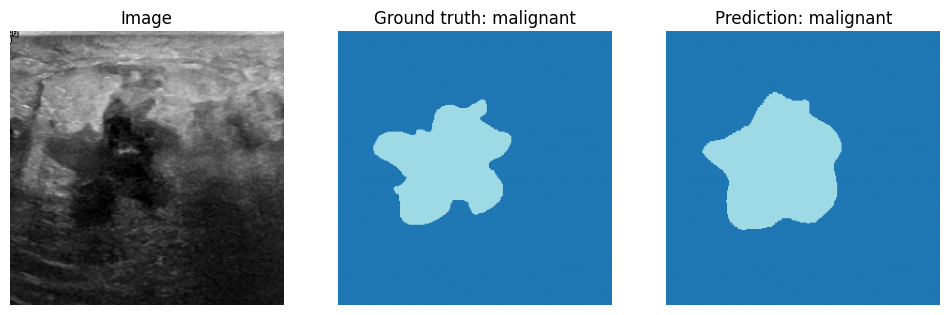

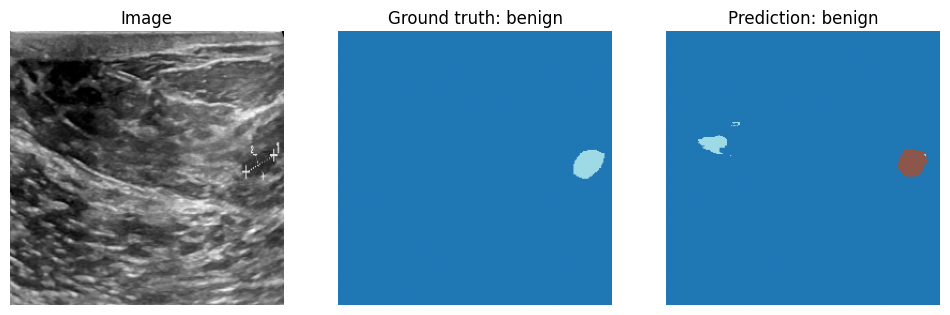

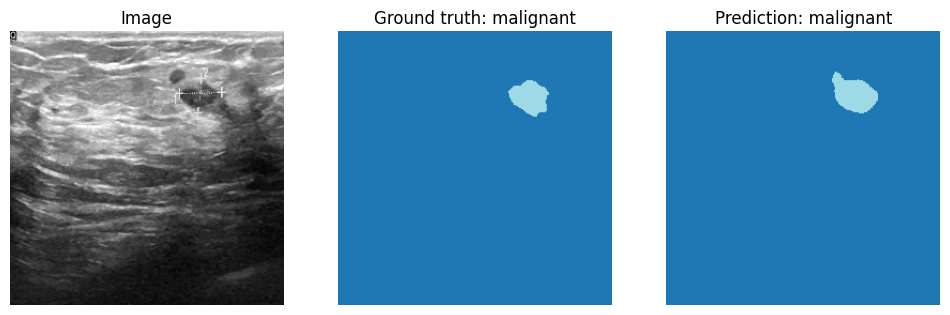

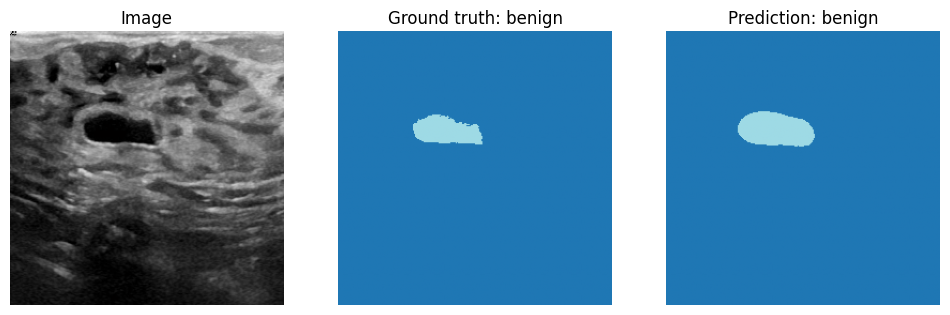

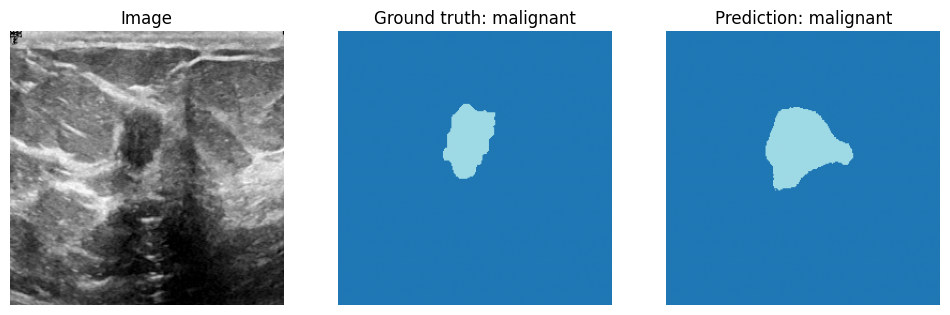

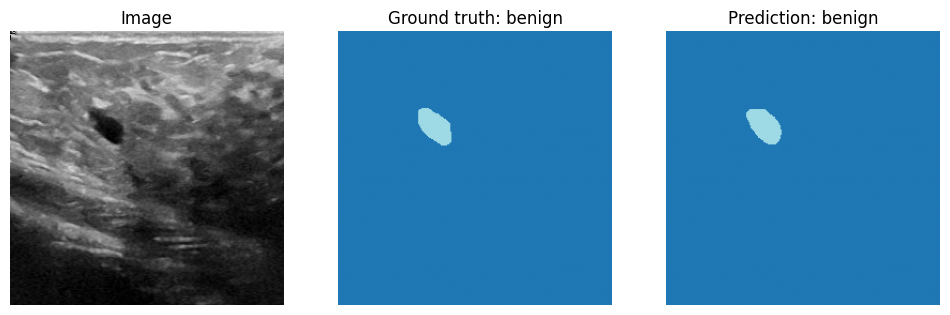

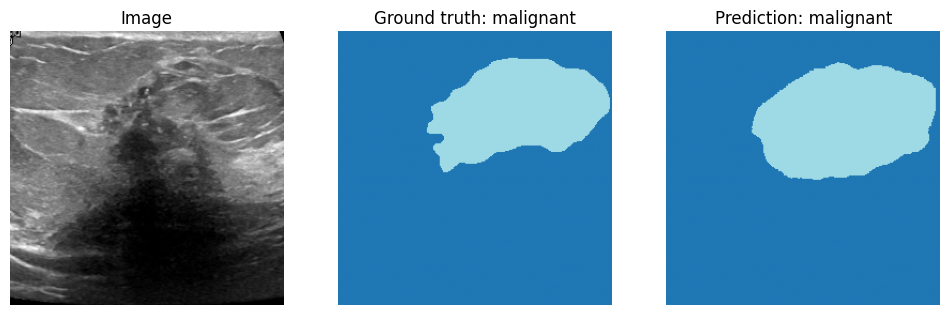

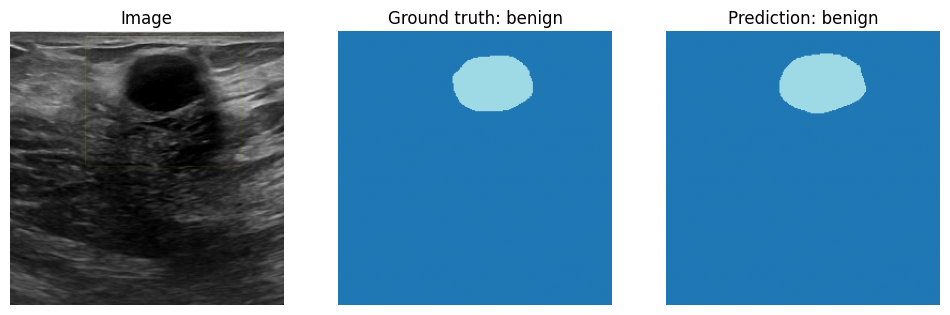

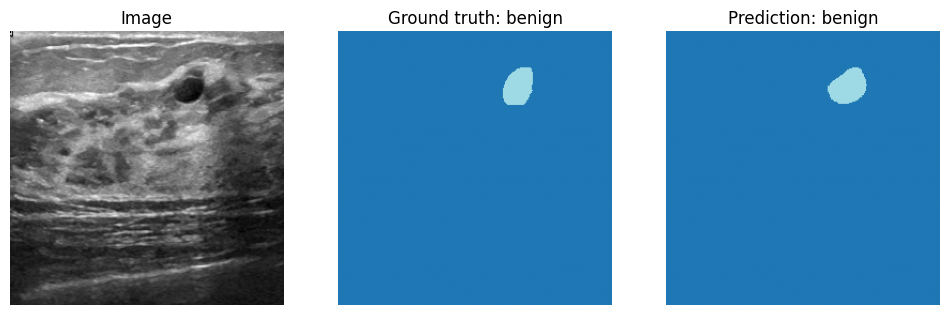

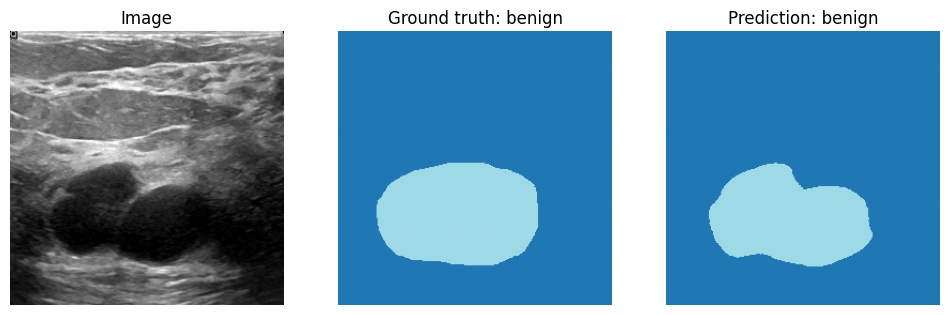

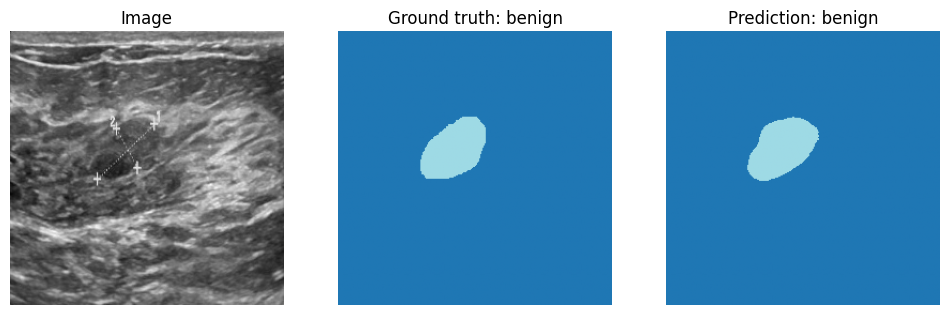

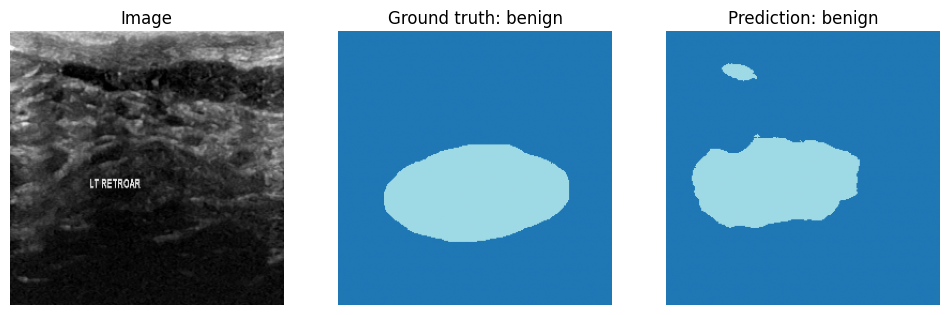

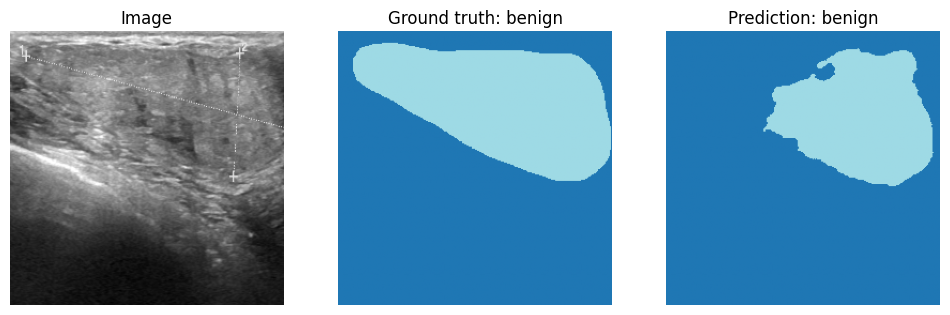

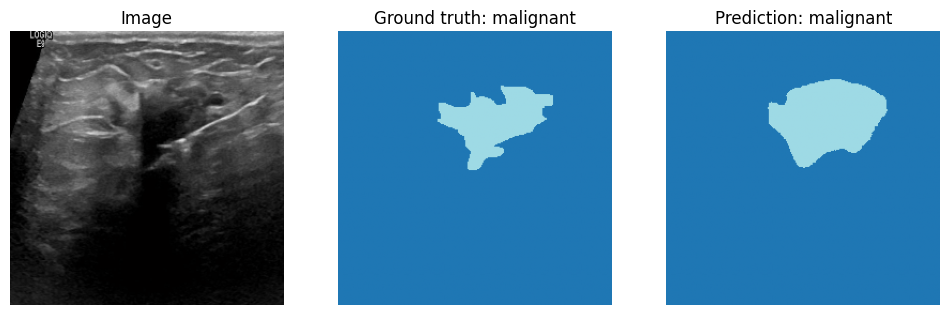

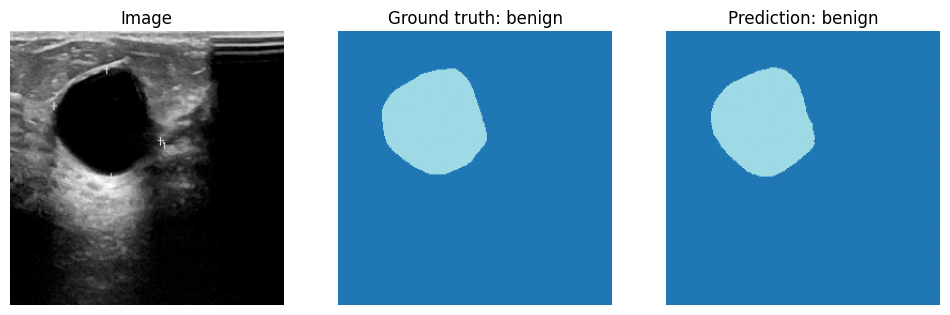

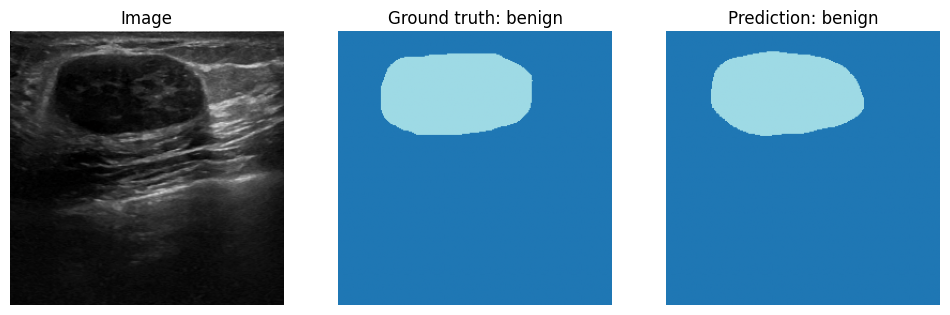

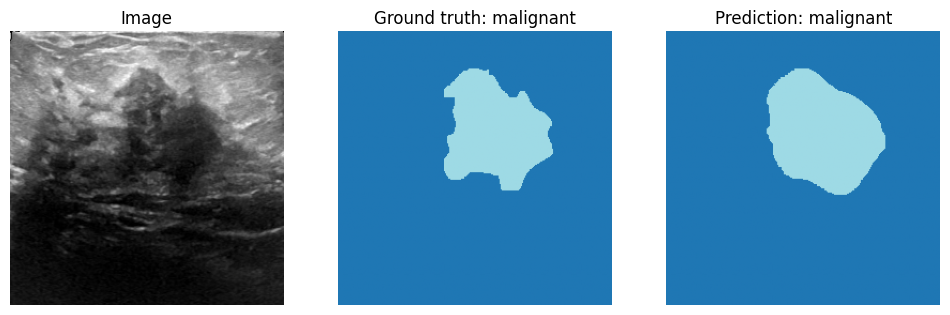

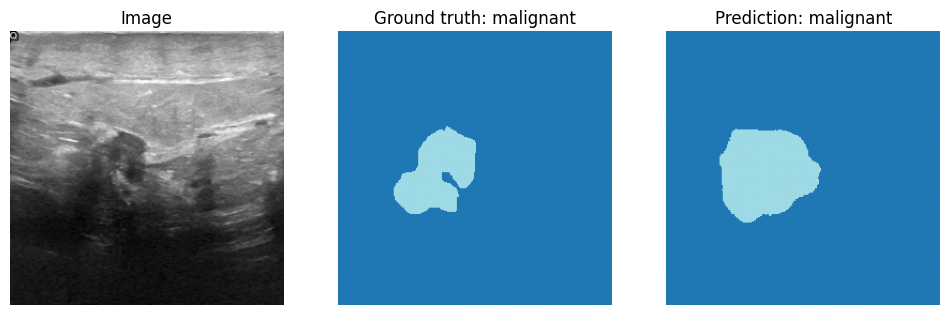

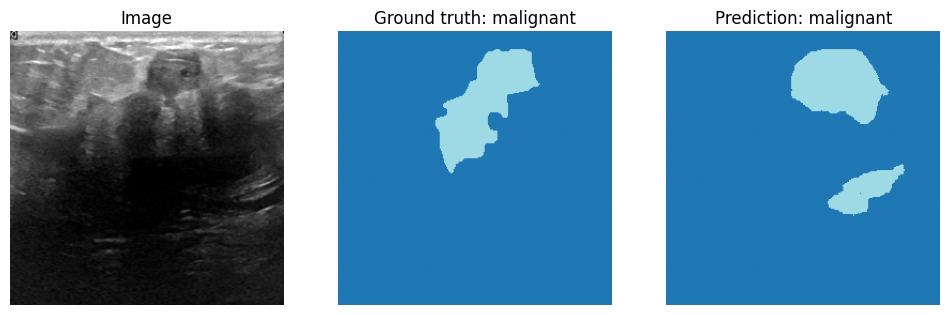

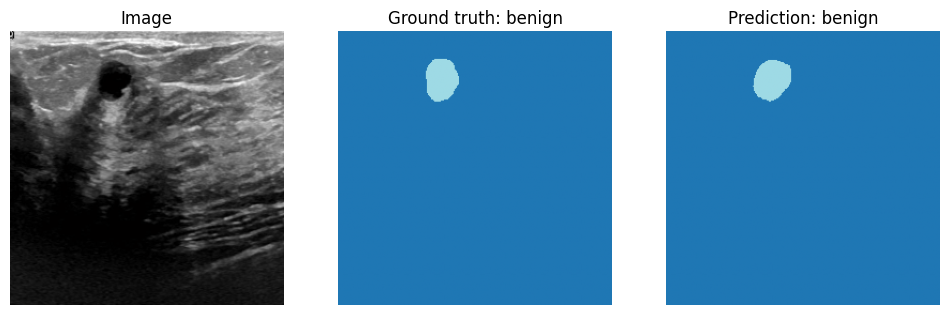

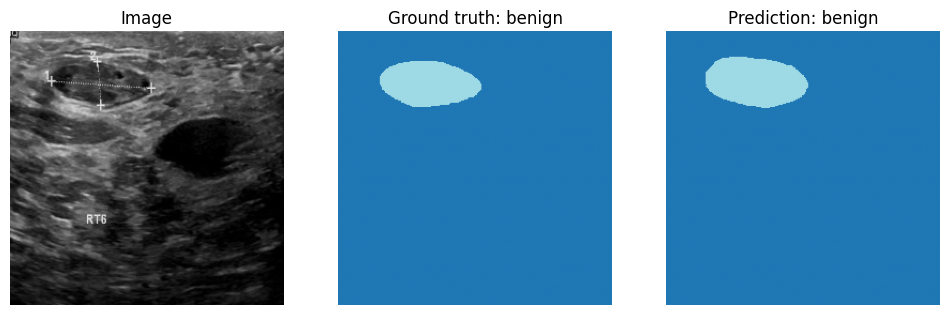

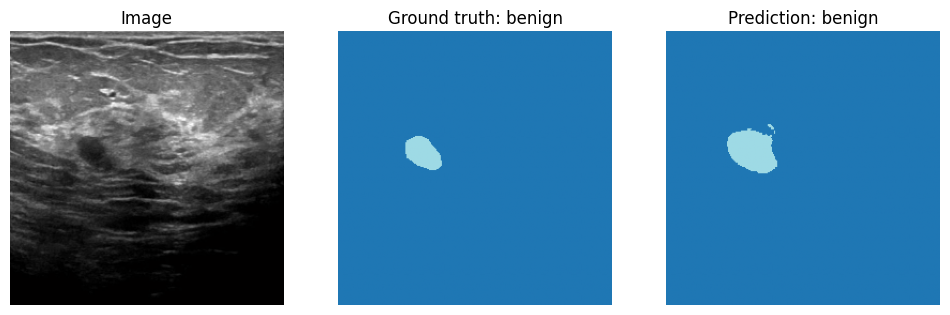

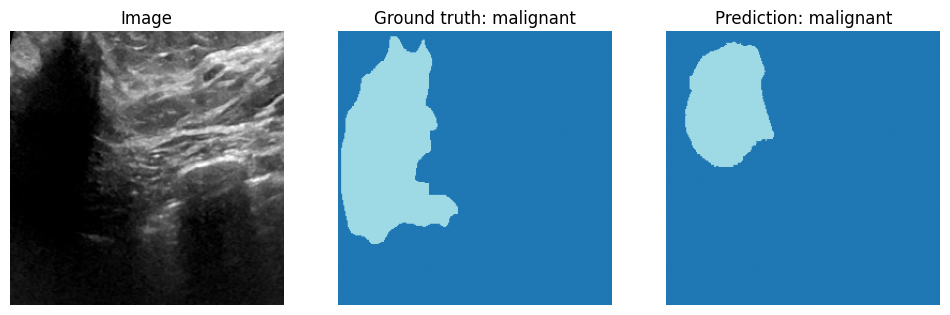

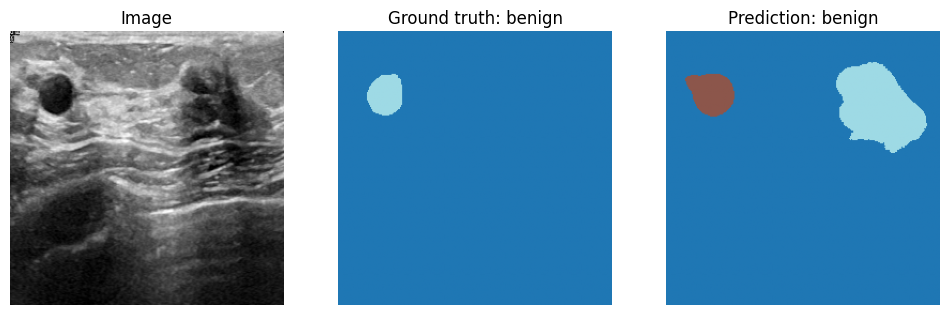

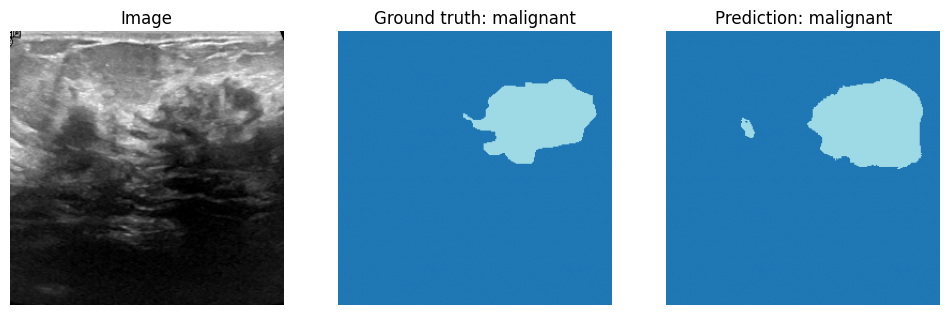

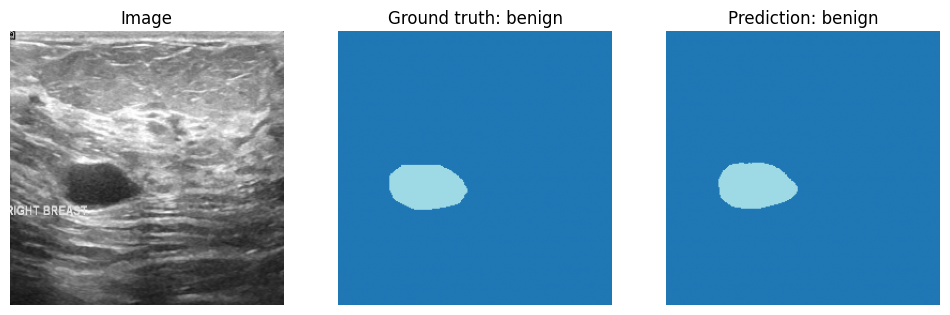

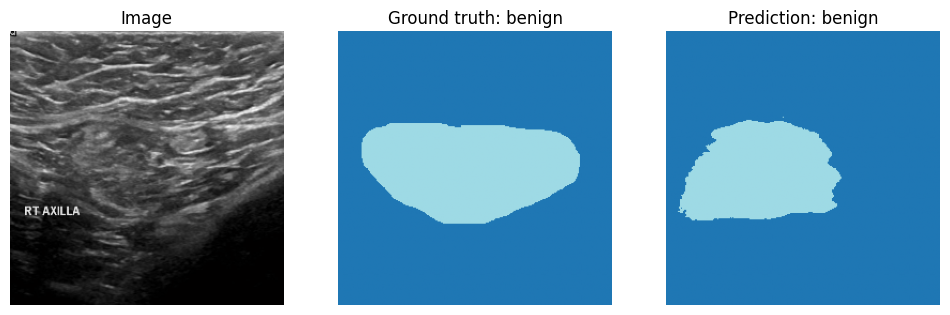

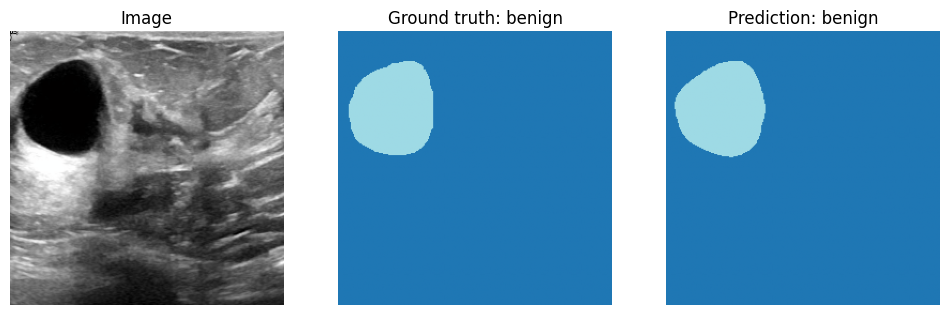

In [29]:
import numpy as np

# Fetch a batch from the test loader
images, masks, class_ids = next(iter(val_loader))

class_names = [SegmentationImageFolder.SEGMENTATION_CLASSES[class_id + 1] for class_id in class_ids]

# Switch the model to evaluation mode
with torch.inference_mode():
    model.eval()
    logits = model(images)  # Get raw logits from the model

# Apply softmax to get class probabilities
# Shape: [batch_size, num_classes, H, W]

pr_masks = logits.softmax(dim=1)
# Convert class probabilities to predicted class labels
pr_masks = pr_masks.argmax(dim=1)  # Shape: [batch_size, H, W]

# Visualize a few samples (image, ground truth mask, and predicted mask)
for idx, (image, gt_mask, pr_mask, cn) in enumerate(zip(images, masks, pr_masks, class_names)):
    if idx <= 32:  # Visualize first 5 samples
        plt.figure(figsize=(12, 6))

        # Original Image
        plt.subplot(1, 3, 1)
        img = image.permute(1, 2, 0).numpy()
        
        # Reverse normalization and scaling if mean/std provided
        if mean is not None and std is not None:
            img = img * std + mean  # Denormalize
        img = np.clip(img, 0, 1)  # Clip to valid range
        
        plt.imshow(
            img
        )  # Convert CHW to HWC for plotting
        plt.title("Image")
        plt.axis("off")

        # Ground Truth Mask
        plt.subplot(1, 3, 2)
        plt.imshow(gt_mask.cpu().numpy(), cmap="tab20")  # Visualize ground truth mask
        plt.title(f"Ground truth: {cn}")
        plt.axis("off")

        # Predicted Mask
        plt.subplot(1, 3, 3)
        plt.imshow(pr_mask.cpu().numpy(), cmap="tab20")  # Visualize predicted mask
        plt.title(f"Prediction: {cn}")
        plt.axis("off")

        # Show the figure
        plt.show()
    else:
        break